In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [3]:
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

In [4]:
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [5]:
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [6]:
df.shape

(23486, 11)

In [7]:
df.columns

Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


In [9]:
df.isnull().sum()

Unnamed: 0                    0
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

Analyze rating distribution

In [10]:
df['Rating'].value_counts().sort_index()

Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64

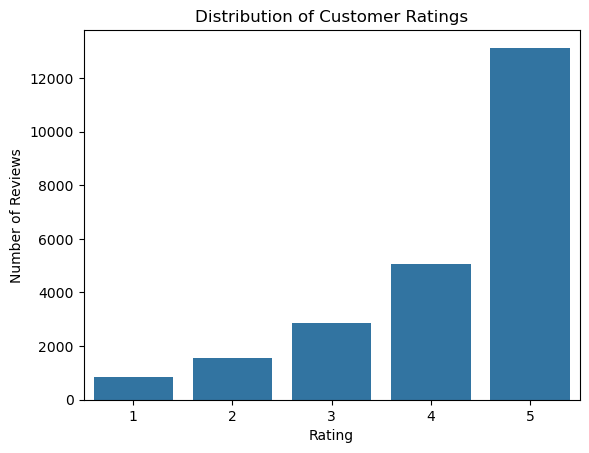

In [11]:
sns.countplot(data=df,x="Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Customer Ratings")
plt.show()

In [12]:
print("avg rating:",df['Rating'].mean())
print("median rating:",df['Rating'].median())
print("most common rating:",df['Rating'].mode()[0])

avg rating: 4.196031678446734
median rating: 5.0
most common rating: 5


Analyze recommendation patterns

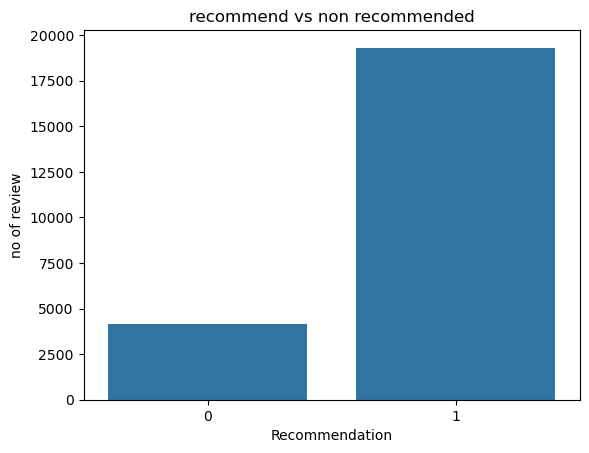

In [13]:
# 1 = recommended
# 0 = not recommended
df['Recommended IND'].value_counts()
sns.countplot(data=df,x="Recommended IND")
plt.title("recommend vs non recommended")
plt.xlabel("Recommendation")
plt.ylabel("no of review")
plt.show()

Calculate the recommendation percentage

In [14]:
recommendation_percentage = (
    df['Recommended IND'].mean() * 100
)

print("Recommendation Percentage:",round(recommendation_percentage,2), "%")

Recommendation Percentage: 82.24 %


Compare ratings with recommendations

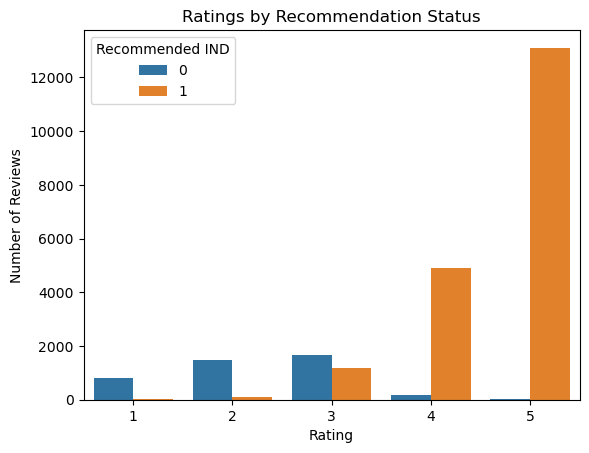

In [15]:
sns.countplot(data=df,x='Rating',hue="Recommended IND")
plt.title("Ratings by Recommendation Status")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

Gaussian Mixture Model (GMM)

In [16]:
data = df[['Rating','Positive Feedback Count']].dropna().copy()

In [17]:
gmm = GaussianMixture(n_components=3,random_state=42)
data['cluster'] = gmm.fit_predict(data)

In [18]:
data.head()

,Rating,Positive Feedback Count,cluster
0,4,0,0
1,5,4,2
2,3,0,2
3,5,0,0
4,5,6,2


In [19]:
data['cluster'].value_counts()

cluster
0    11299
2     9478
1     2709
Name: count, dtype: int64

Visualize the customer segments

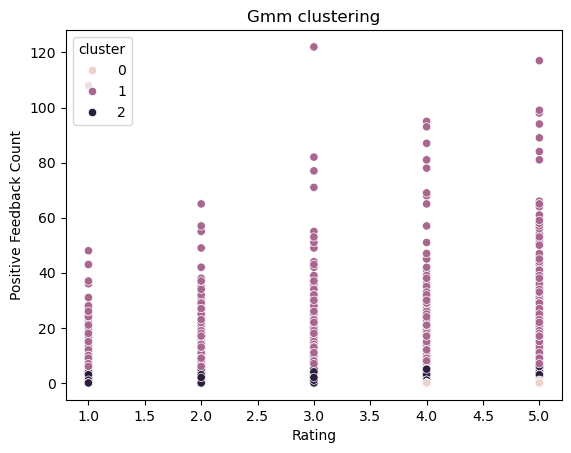

In [20]:
sns.scatterplot(data=data,x="Rating",y="Positive Feedback Count",hue="cluster")
plt.title("Gmm clustering")
plt.show()

In [21]:
print(
    data.groupby("cluster").mean().round(2)
)

         Rating  Positive Feedback Count
cluster                                 
0          4.78                     0.21
1          3.88                    13.92
2          3.59                     2.06


Detect anomalies using Isolation Forest

In [22]:
data = df[['Rating','Positive Feedback Count']].dropna().copy()
model = IsolationForest(contamination=0.05,random_state=42)
data['anomaly'] = model.fit_predict(data)

In [23]:
data['anomaly'].value_counts()

anomaly
 1    22321
-1     1165
Name: count, dtype: int64

Plot the anomalies

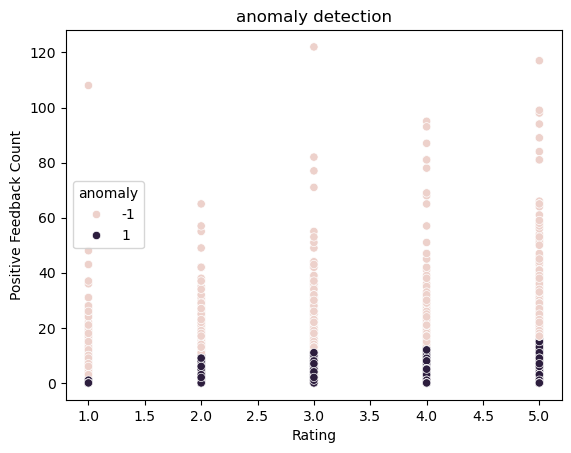

In [24]:
sns.scatterplot(data=data,x="Rating",y="Positive Feedback Count",hue="anomaly")
plt.title("anomaly detection")
plt.show()

Compare ratings and recommendations statistically

In [25]:
df.groupby('Recommended IND')["Rating"].mean()

Recommended IND
0    2.303691
1    4.604794
Name: Rating, dtype: float64

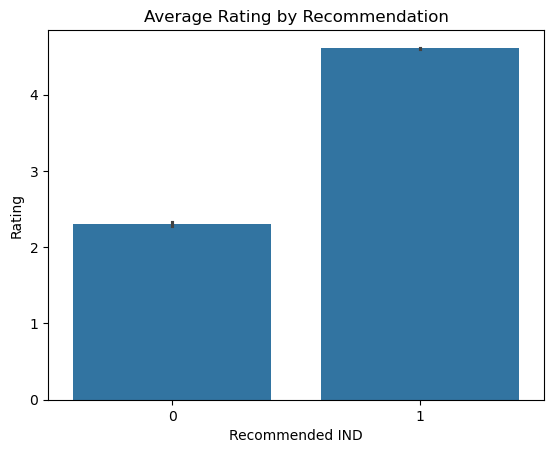

In [26]:
sns.barplot(data=df, x="Recommended IND", y="Rating")
plt.title("Average Rating by Recommendation")
plt.show()

In [27]:
print("total review:",len(df))

total review: 23486


In [28]:
print("avg rating:",df['Rating'].mean())

avg rating: 4.196031678446734


In [29]:
print("Recommendation rate:",df['Recommended IND'].mean())

Recommendation rate: 0.8223622583666865


In [30]:
print("GMM Clusters:", data["cluster"].nunique()
      if "cluster" in data.columns else "Check GMM data")

print("Total Anomalies:", (data["anomaly"] == -1).sum()
      if "anomaly" in data.columns else "Check anomaly data")

GMM Clusters: Check GMM data
Total Anomalies: 1165
